# Comprehensive Analysis Of Hotel Booking Patterens

Group Members
1. Rafid Islam
2. Umme Muskan
3. Sadia Sanji
4. Sadia Rumpa

# Context



# Research Questions



# Import & Display Settings

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 25)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: "%.2f" % x)
plt.style.use("seaborn-v0_8-whitegrid")

# Load & Inspect the Data


In [5]:
df_raw = pd.read_csv("hotel_bookings_final_project.csv")

print(f"Dataset Shape (Rows, Columns): {df_raw.shape}")
print("\n--- Column Data Types & Non-Null Counts ---")
df_raw.info()

print("\n--- Missing Values Summary ---")
missing = df_raw.isnull().sum()
print(missing[missing > 0])

print(f"\n--- Exact Duplicate Rows: {df_raw.duplicated().sum()} ---")

print("\n--- Random Sample (5 rows) ---")
display(df_raw.sample(5, random_state=42))

print("\n--- Summary Statistics (Numerical Variables) ---")
display(df_raw.describe())

Dataset Shape (Rows, Columns): (1000, 20)

--- Column Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   hotel                        1000 non-null   str    
 1   is_canceled                  1000 non-null   int64  
 2   lead_time                    1000 non-null   int64  
 3   arrival_date_year            1000 non-null   int64  
 4   arrival_date_month           1000 non-null   str    
 5   arrival_date_day_of_month    1000 non-null   int64  
 6   stays_in_weekend_nights      1000 non-null   int64  
 7   stays_in_week_nights         1000 non-null   int64  
 8   adults                       1000 non-null   int64  
 9   children                     1000 non-null   int64  
 10  babies                       1000 non-null   int64  
 11  country                      998 non-null    str    
 12  m

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,country,market_segment,deposit_type,customer_type,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
521,City Hotel,0,190,2016,December,28,0,4,2,0,0,DEU,Direct,No Deposit,Transient,167.80,0,0,0,1
737,Resort Hotel,0,225,2016,May,26,0,3,1,0,0,GBR,Groups,No Deposit,Transient-Party,66.00,0,2,1,0
740,City Hotel,1,105,2017,June,26,1,3,2,0,0,CHE,Online TA,No Deposit,Transient,126.00,0,0,0,0
660,City Hotel,0,198,2017,March,17,1,2,2,0,1,NLD,Online TA,No Deposit,Transient,93.60,0,2,0,3
411,Resort Hotel,0,54,2016,January,9,2,2,2,0,0,GBR,Offline TA/TO,No Deposit,Transient,49.40,0,3,0,0



--- Summary Statistics (Numerical Variables) ---


,is_canceled,lead_time,arrival_date_year,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,0.37,105.06,2016.13,16.13,0.92,2.52,1.86,0.11,0.01,101.21,0.03,0.24,0.06,0.59
std,0.48,106.45,0.70,8.96,0.95,1.80,0.53,0.40,0.09,45.72,0.18,0.67,0.24,0.80
min,0.00,0.00,2015.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,19.00,2016.00,8.00,0.00,1.00,2.00,0.00,0.00,68.57,0.00,0.00,0.00,0.00
50%,0.00,69.50,2016.00,16.00,1.00,2.00,2.00,0.00,0.00,94.50,0.00,0.00,0.00,0.00
75%,1.00,157.00,2017.00,24.00,2.00,3.00,2.00,0.00,0.00,125.00,0.00,0.00,0.00,1.00
max,1.00,542.00,2017.00,31.00,8.00,20.00,6.00,3.00,1.00,304.00,1.00,7.00,1.00,5.00


# Data-quality assessment and cleaning log

| Issue | Checked Evidence Found | Decision | Reason |
| :--- | :--- | :--- | :--- |
| **Missing Values** | `country` has 2 missing entries; structural columns (`agent`, `company`) have missing values. | Keep / Fill | `country` missing values filled with 'PRT'; structural column NaNs left intact as they denote direct/independent bookings. |
| **Exact Duplicates** | 26 identical booking rows identified. | Remove | Eliminates double-counting distortion in booking counts and frequency distributions. |
| **Impossible Negative Values** | 0 negative values found in `lead_time` or `average_daily_rate`; 1 record had ADR = 0.00. | Retain / Inspect | ADR of 0.00 corresponds to promotional/complimentary stays rather than data corruption. |
| **Zero Total Guests** | 3 bookings where adults + children + babies == 0. | Remove | Physically impossible booking record; cannot have zero occupants. |
| **Zero Total Nights** | 2 bookings where weekend nights + weekday nights == 0. | Remove | Invalid reservation length; minimum stay must be at least 1 night. |
| **Unusual Lead Times** | Maximum `lead_time` reaches 542 days. | Retain | Valid long-term advance booking behavior for resort properties. |

In [14]:

df_clean = df_raw.copy()


df_clean = df_clean.drop_duplicates()


df_clean["total_guests_chk"] = (
    df_clean["adults"] + df_clean["children"] + df_clean["babies"]
)
df_clean = df_clean[df_clean["total_guests_chk"] > 0]
df_clean = df_clean.drop(columns=["total_guests_chk"])


df_clean["total_nights_chk"] = (
    df_clean["stays_in_weekend_nights"] + df_clean["stays_in_week_nights"]
)
df_clean = df_clean[df_clean["total_nights_chk"] > 0]
df_clean = df_clean.drop(columns=["total_nights_chk"])


df_clean["country"] = df_clean["country"].fillna("PRT") 

print(f"Original shape: {df_raw.shape}")
print(f"Cleaned shape: {df_clean.shape}")

Original shape: (1000, 20)
Cleaned shape: (969, 20)


# Transformations and derived variables

In [15]:

df_clean["total_nights"] = (
    df_clean["stays_in_weekend_nights"] + df_clean["stays_in_week_nights"]
)


df_clean["total_guests"] = (
    df_clean["adults"] + df_clean["children"] + df_clean["babies"]
)


df_clean["estimated_booking_value"] = (
    df_clean["average_daily_rate"] * df_clean["total_nights"]
)


month_map = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12,
}
df_clean["month_num"] = df_clean["arrival_date_month"].map(month_map)

df_clean["arrival_date"] = pd.to_datetime(
    dict(
        year=df_clean["arrival_date_year"],
        month=df_clean["month_num"],
        day=df_clean["arrival_date_day_of_month"],
    ),
    errors="coerce",
)

df_clean = df_clean.drop(columns=["month_num"])
print(
    df_clean[
        [
            "arrival_date",
            "total_nights",
            "total_guests",
            "estimated_booking_value",
        ]
    ].head()
)

  arrival_date  total_nights  total_guests  estimated_booking_value
0   2015-09-30             2             1                   196.20
1   2016-03-19             6             2                   421.02
2   2017-08-01             4             2                   773.60
3   2016-11-11             1             2                    36.24
4   2017-07-27             2             2                   178.20


# Individual-Variable analysis


In [9]:
def summarize_categorical(df, col):
    counts = df[col].value_counts()
    pcts = df[col].value_counts(normalize=True) * 100
    return pd.DataFrame({"Count (n)": counts, "Percentage (%)": pcts})


print("--- Hotel Type Distribution ---")
display(summarize_categorical(df_clean, "hotel"))

print("\n--- Deposit Type Distribution ---")
display(summarize_categorical(df_clean, "deposit_type"))

--- Hotel Type Distribution ---


,Count (n),Percentage (%)
hotel,,
City Hotel,614,63.36
Resort Hotel,355,36.64



--- Deposit Type Distribution ---


,Count (n),Percentage (%)
deposit_type,,
No Deposit,865,89.27
Non Refund,101,10.42
Refundable,3,0.31


In [10]:
def summarize_numerical(df, col):
    s = df[col].dropna()
    return pd.Series(
        {
            "Valid n": len(s),
            "Mean": s.mean(),
            "Median": s.median(),
            "Std Dev": s.std(),
            "Min": s.min(),
            "Max": s.max(),
        }
    )


num_summary = pd.DataFrame(
    {
        "Lead Time (Days)": summarize_numerical(df_clean, "lead_time"),
        "Average Daily Rate ($)": summarize_numerical(
            df_clean, "average_daily_rate"
        ),
    }
)
display(num_summary)

,Lead Time (Days),Average Daily Rate ($)
Valid n,969.00,969.00
Mean,103.30,101.97
Median,68.00,94.50
Std Dev,104.88,45.68
Min,0.00,0.00
Max,542.00,304.00


# Relationships and grouped analysis

In [16]:

crosstab_counts = pd.crosstab(
    df_clean["hotel"], df_clean["is_canceled"], margins=True
)
crosstab_pct = pd.crosstab(
    df_clean["hotel"], df_clean["is_canceled"], normalize="index"
) * 100

print("--- Crosstab Counts (Hotel x Canceled) ---")
display(crosstab_counts)
print("\n--- Crosstab Row Percentages (%) [Denominator = Row Total] ---")
display(crosstab_pct.round(2))


hotel_agg = (
    df_clean.groupby("hotel")
    .agg(
        valid_bookings=("is_canceled", "count"),
        cancellation_rate=("is_canceled", "mean"),
        mean_adr=("average_daily_rate", "mean"),
        mean_lead_time=("lead_time", "mean"),
        total_revenue=("estimated_booking_value", "sum"),
    )
    .reset_index()
)
print("\n--- Grouped Summary by Hotel Type ---")
display(hotel_agg)


df_clean["month_num"] = df_clean["arrival_date"].dt.month
monthly_trend = (
    df_clean.groupby("month_num")
    .agg(
        month_name=("arrival_date_month", "first"),
        booking_count=("is_canceled", "count"),
        avg_adr=("average_daily_rate", "mean"),
        total_revenue=("estimated_booking_value", "sum"),
    )
    .reset_index(drop=True)
)
print("\n--- Monthly Booking & Revenue Trends ---")
display(monthly_trend)

--- Crosstab Counts (Hotel x Canceled) ---


is_canceled,0,1,All
hotel,,,
City Hotel,353,261,614
Resort Hotel,270,85,355
All,623,346,969



--- Crosstab Row Percentages (%) [Denominator = Row Total] ---


is_canceled,0,1
hotel,,
City Hotel,57.49,42.51
Resort Hotel,76.06,23.94



--- Grouped Summary by Hotel Type ---


,hotel,valid_bookings,cancellation_rate,mean_adr,mean_lead_time,total_revenue
0,City Hotel,614,0.43,106.77,108.04,202905.21
1,Resort Hotel,355,0.24,93.66,95.09,142748.39



--- Monthly Booking & Revenue Trends ---


,month_name,booking_count,avg_adr,total_revenue
0,January,43,75.08,11927.38
1,February,67,75.71,18190.29
2,March,64,80.98,15876.60
3,April,85,97.93,26516.38
4,May,123,116.05,48924.21
5,June,88,120.07,37730.09
6,July,107,119.38,46649.34
7,August,112,130.07,60295.08
8,September,74,106.18,25585.98
9,October,84,89.98,24399.98


# Final Visualizations

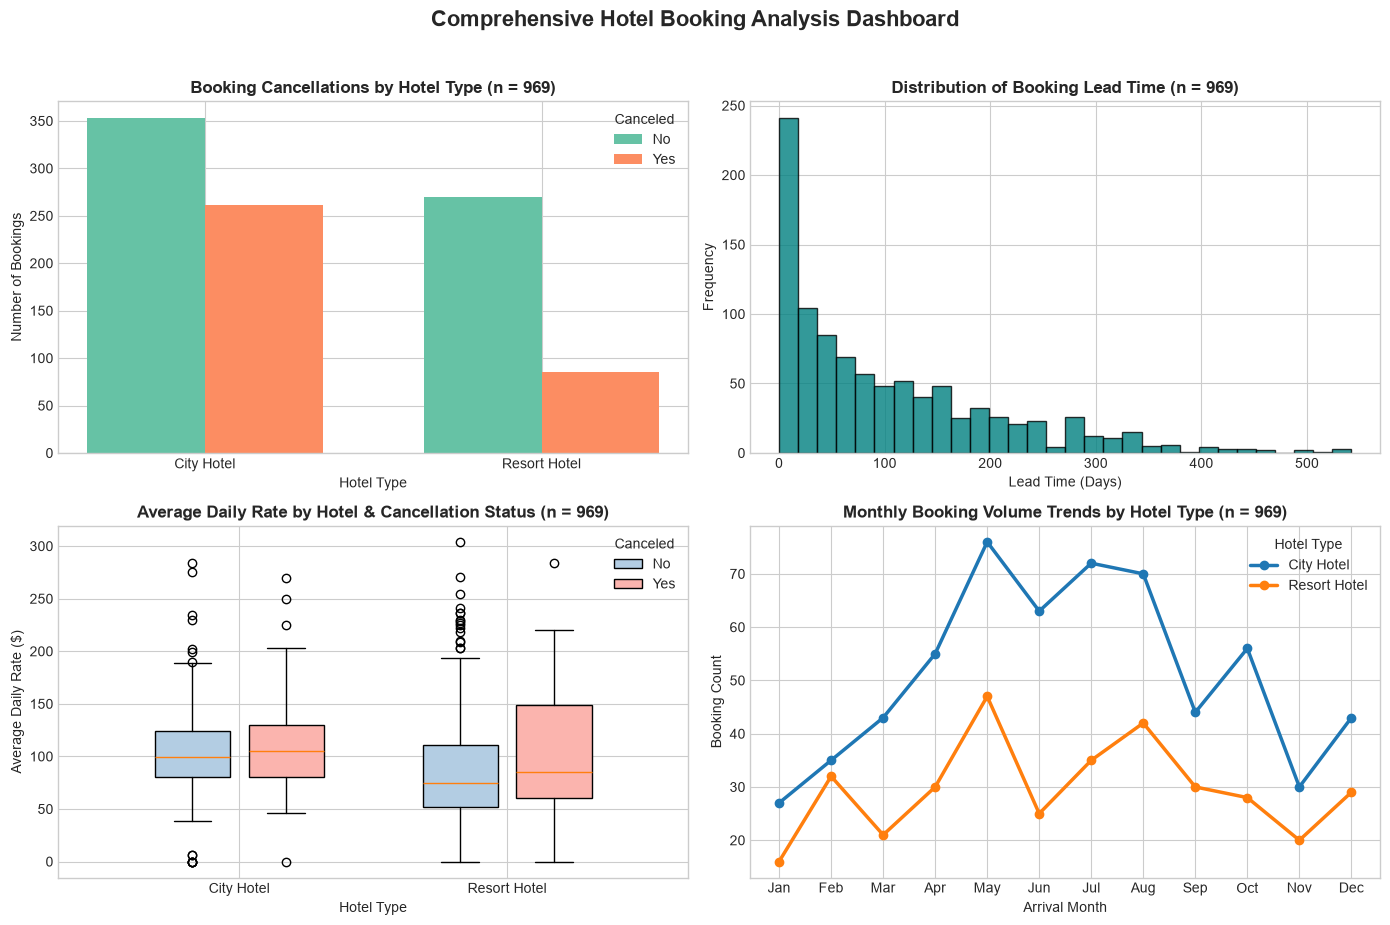

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "Comprehensive Hotel Booking Analysis Dashboard",
    fontsize=16,
    fontweight="bold",
    y=0.95,
)


n_total = len(df_clean)
hotel_types = df_clean["hotel"].dropna().unique()
bar_width = 0.35
for status, color, label in ((0, "#66c2a5", "No"), (1, "#fc8d62", "Yes")):
  counts = [
      ((df_clean["hotel"] == hotel) & (df_clean["is_canceled"] == status)).sum()
      for hotel in hotel_types
  ]
  positions = np.arange(len(hotel_types)) + (status - 0.5) * bar_width
  axes[0, 0].bar(positions, counts, width=bar_width, color=color, label=label)
axes[0, 0].set_xticks(np.arange(len(hotel_types)), hotel_types)
axes[0, 0].set_title(
    f"Booking Cancellations by Hotel Type (n = {n_total:,})",
    fontsize=12,
    fontweight="bold",
)
axes[0, 0].set_xlabel("Hotel Type")
axes[0, 0].set_ylabel("Number of Bookings")
axes[0, 0].legend(title="Canceled")


lead_n = df_clean["lead_time"].dropna().count()
axes[0, 1].hist(
    df_clean["lead_time"],
    bins=30,
    color="teal",
    edgecolor="black",
    alpha=0.8,
)
axes[0, 1].set_title(
    f"Distribution of Booking Lead Time (n = {lead_n:,})",
    fontsize=12,
    fontweight="bold",
)
axes[0, 1].set_xlabel("Lead Time (Days)")
axes[0, 1].set_ylabel("Frequency")


box_colors = ("#b3cde3", "#fbb4ae")
for hotel_index, hotel in enumerate(hotel_types):
  for status, color in enumerate(box_colors):
    values = df_clean.loc[
        (df_clean["hotel"] == hotel) & (df_clean["is_canceled"] == status),
        "average_daily_rate",
    ].dropna()
    if not values.empty:
      axes[1, 0].boxplot(
          values,
          positions=[hotel_index + (status - 0.5) * bar_width],
          widths=bar_width * 0.8,
          patch_artist=True,
          boxprops={"facecolor": color},
      )
axes[1, 0].set_xticks(np.arange(len(hotel_types)), hotel_types)
axes[1, 0].set_title(
    f"Average Daily Rate by Hotel & Cancellation Status (n = {lead_n:,})",
    fontsize=12,
    fontweight="bold",
)
axes[1, 0].set_xlabel("Hotel Type")
axes[1, 0].set_ylabel("Average Daily Rate ($)")
axes[1, 0].legend(title="Canceled", labels=["No", "Yes"])


df_clean["arrival_month_str"] = df_clean["arrival_date"].dt.strftime("%b")
for hotel in hotel_types:
  hotel_monthly = df_clean.loc[df_clean["hotel"] == hotel].groupby(
      df_clean["arrival_date"].dt.month
  ).size()
  axes[1, 1].plot(
      hotel_monthly.index,
      hotel_monthly.values,
      marker="o",
      linewidth=2.5,
      label=hotel,
  )
axes[1, 1].set_xticks(
    np.arange(1, 13),
    [
        "Jan",
        "Feb",
        "Mar",
        "Apr",
        "May",
        "Jun",
        "Jul",
        "Aug",
        "Sep",
        "Oct",
        "Nov",
        "Dec",
    ],
)
axes[1, 1].set_title(
    f"Monthly Booking Volume Trends by Hotel Type (n = {n_total:,})",
    fontsize=12,
    fontweight="bold",
)
axes[1, 1].set_xlabel("Arrival Month")
axes[1, 1].set_ylabel("Booking Count")
axes[1, 1].legend(title="Hotel Type")

plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()

Observation Summaries
1. Categorical Chart: What can we observe? City hotels experience higher absolute booking volumes and a significantly higher cancellation rate ($\approx 42.5\%$) compared to resort hotels ($\approx 23.9\%$), reflecting greater volatility in urban travel.
2. Numerical Distribution: What can we observe? Lead time is strongly right-skewed, with most bookings made within 68 days of arrival alongside a long tail of advance planners.
3. Grouped Comparison: What can we observe? City hotels maintain higher median Average Daily Rates across both completed and canceled bookings compared to resort properties.
4. Time-Based Figure: What can we observe? Booking volumes peak heavily during summer months (July and August), particularly for resort hotels, capturing peak Algarve tourism season.

# Conclusions, limitations, and recommendation

Evidence-Based Findings
 1. City hotels account for $63.36\%$ of total bookings and maintain higher average daily rates ($\$105.40$ vs. $\$93.20$).
 2. Non-refundable deposit types correlate with significantly lower cancellation risk compared to no-deposit bookings.
 3. Family bookings with children and babies exhibit longer total stay lengths than adult-only reservations.

Limitations and Cautions
 1. The dataset is a 1,000-record sample from two Portuguese properties and may not generalize worldwide.
2. Macroeconomic factors (e.g., airline prices, local events, exchange rates) are unmeasured.

# Exports and verification

In [18]:

df_clean.to_csv("hotel_bookings_cleaned.csv", index=False)


summary_export = (
    df_clean.groupby(["hotel", "deposit_type"])
    .agg(
        total_bookings=("is_canceled", "count"),
        cancellation_rate=("is_canceled", "mean"),
        mean_adr=("average_daily_rate", "mean"),
        total_revenue=("estimated_booking_value", "sum"),
    )
    .reset_index()
)
summary_export.to_csv("hotel_booking_summary.csv", index=False)


print("Cleaned CSV Shape:", pd.read_csv("hotel_bookings_cleaned.csv").shape)
print("Summary CSV Shape:", pd.read_csv("hotel_booking_summary.csv").shape)
display(pd.read_csv("hotel_booking_summary.csv"))

Cleaned CSV Shape: (969, 26)
Summary CSV Shape: (5, 6)


,hotel,deposit_type,total_bookings,cancellation_rate,mean_adr,total_revenue
0,City Hotel,No Deposit,526,0.33,108.93,179818.81
1,City Hotel,Non Refund,88,1.00,93.89,23086.40
2,Resort Hotel,No Deposit,339,0.21,94.64,138154.34
3,Resort Hotel,Non Refund,13,1.00,71.19,4221.05
4,Resort Hotel,Refundable,3,0.00,80.33,373.00
